In [1]:
import numpy as np
from numpy import pi

def generate_spiral(a, b, N, noise_factor=0):

    theta = np.sqrt(np.random.rand(N))*4*pi
    r = a + b*theta
    x = np.array([np.cos(theta)*r, np.sin(theta)*r]).T
    x += np.expand_dims(noise_factor*r,1)*np.random.randn(N,2)
    return x

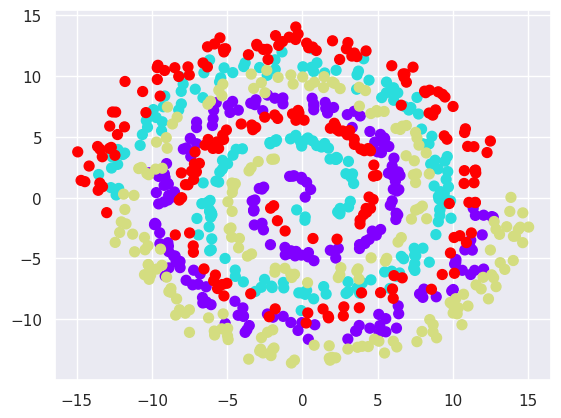

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

N = 200
a = 1.75
b = 1
noise_factor = 0.05

x1 = generate_spiral(0,b,N,noise_factor)
x2 = generate_spiral(0,-b,N,noise_factor)
x3 = generate_spiral(a,b,N,noise_factor)
x4 = generate_spiral(-a,-b,N,noise_factor)

X = np.concatenate((x1,x2,x3,x4),axis=0)
Y = np.ravel(np.concatenate((np.zeros((N,1)),np.ones((N,1)),2*np.ones((N,1)),3*np.ones((N,1))), axis=0))


plt.scatter(X[:, 0], X[:, 1], c=Y, s=50, cmap='rainbow');

**3. Como primera actividad de la tarea deberás dividir el conjunto de datos en subconjuntos de entrenamiento y prueba, utilizando la función train_test_split de sklearn, con una proporción adecuada para cada uno, dado el tamaño del conjunto de datos.**

In [22]:
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.ensemble import GradientBoostingClassifier

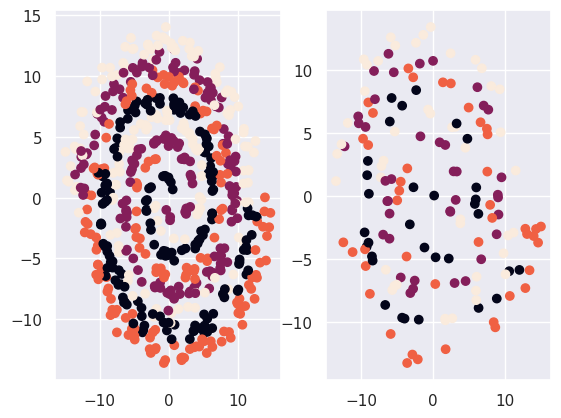

In [76]:
random_state = 0
np.random.seed(random_state)
X_train, X_test, Y_train, Y_test= train_test_split(X,Y, test_size=0.2, random_state=random_state)

fig, (ax1,ax2)= plt.subplots(1,2)
ax1.scatter(X_train[:,0], X_train[:,1], c=Y_train)
ax2.scatter(X_test[:,0], X_test[:,1], c=Y_test)
plt.show()


**4. Entrena al menos 3 modelos basados en las técnicas cubiertas en el módulo 2 del curso. Para cada una, obtenga su rendimiento en los conjuntos de entrenamiento y prueba y comente sobre el nivel de sobreajuste exhibido, en función de la comparación entre modelos.**

Accuracy_train=1.00 | Accuracy_test=0.74


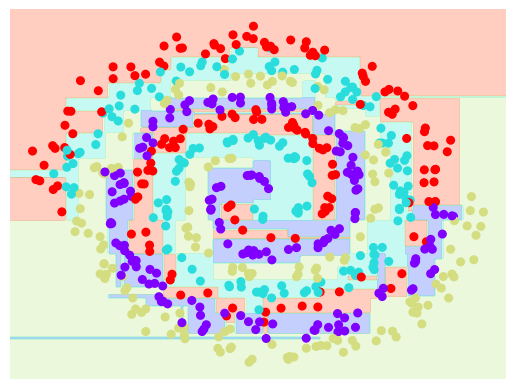

In [75]:
def visualize_classifier(model, X, Y, ax=None, cmap='rainbow'):
  ax = ax or plt.gca()
  ax.scatter(X[:, 0], X[:, 1], c=Y, s=30, cmap=cmap, clim=(Y.min(), Y.max()), zorder=3)
  ax.axis('tight')
  ax.axis('off')
  xlim = ax.get_xlim()
  ylim = ax.get_ylim()
  xx, yy = np.meshgrid(np.linspace(*xlim, num=200), np.linspace(*ylim, num=200))
  Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
  n_classes = len(np.unique(Y))
  contours = ax.contourf(xx, yy, Z, alpha=0.3, levels=np.arange(n_classes + 1) - 0.5, cmap=cmap, zorder=1)
  ax.set(xlim=xlim, ylim=ylim)

def train_y_eval(model, X_train, Y_train, X_test, Y_test):
  model.fit(X_train, Y_train)
  acc_train=metrics.accuracy_score(Y_train, model.predict(X_train))
  acc_test=metrics.accuracy_score(Y_test, model.predict(X_test))
  print(f"Accuracy_train={acc_train:.2f} | Accuracy_test={acc_test:.2f}")

##Modelo 1
tree=DecisionTreeClassifier(random_state=random_state)
train_y_eval(tree, X_train, Y_train, X_test, Y_test)
visualize_classifier(tree, X_train, Y_train)


Accuracy_train=1.00 | Accuracy_test=0.71


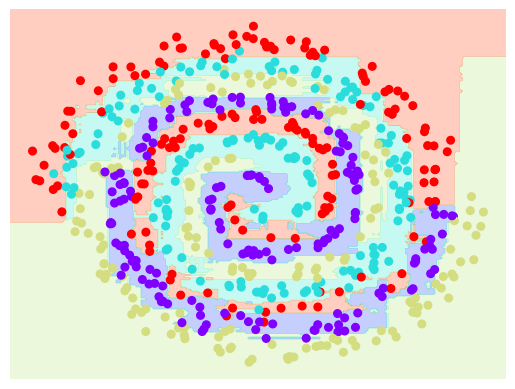

In [74]:
##Modelo 2
forest= RandomForestClassifier(random_state=random_state)
train_y_eval(forest, X_train, Y_train, X_test, Y_test)
visualize_classifier(forest, X_train, Y_train)

Accuracy_train=0.92 | Accuracy_test=0.57


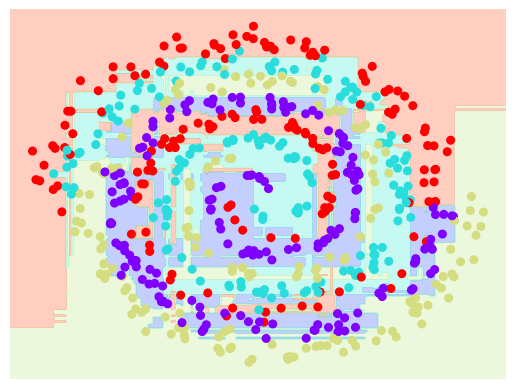

In [73]:
##Modelo 3

grad_boosting=GradientBoostingClassifier(random_state=random_state)
train_y_eval(grad_boosting, X_train, Y_train, X_test, Y_test)
visualize_classifier(grad_boosting, X_train, Y_train)

En los tres modelos, vemos como se presenta un sobreajuste, debido a que el rendimiento en la prueba es menor al rendimiento en la etapa de entrenamiento.

Para el caso del arbol, este tiene un Accuracy en la etapa de entrenamiento del 100% y durante la etapa de prueba de 74%. A su vez, el Random Forest tiene también un 100% de Accuracy en la estapa de entremaiento y de 71% en la etapa de prueba. Ahora bien, el modelo de Gradient Boosting tiene un accuracy del 92% en la etapa de entremiento y de 57% en la etapa de prueba.

Esta brecha de sobre ajuste, es mpás evidente en el modelo del Gradient Boosting, que presenta el peor desempeño durante la fase de prueba, esto, debidoa que al corregir los errores de modelos anteriores de forma secuencial, se tiene un componente de ruido que afecta los resultados del modelo.

A su vez, se hubiera esperado que el Random Forest hubiera mejorado el accuracy durante la etapa de prueba, pero este no fue el caso, ya que el modelo de árbol de decisión presenta un mejor accuracy. Esto puede deberse a al existencia de sólo 2 caracterísitcas en el modelo, lo que reduce la aleatoridad del modelo, por lo que los árboles se encuentran correlacionados entre sí.


**5. Visualiza las superficies de decisión de cada uno de los modelos entrenados, utilizando el esquema presentado en los tutoriales, e identifique los sectores del espacio de características donde se aprecie sobreajuste. Comente sobre las características de estos sectores para cada modelo.**

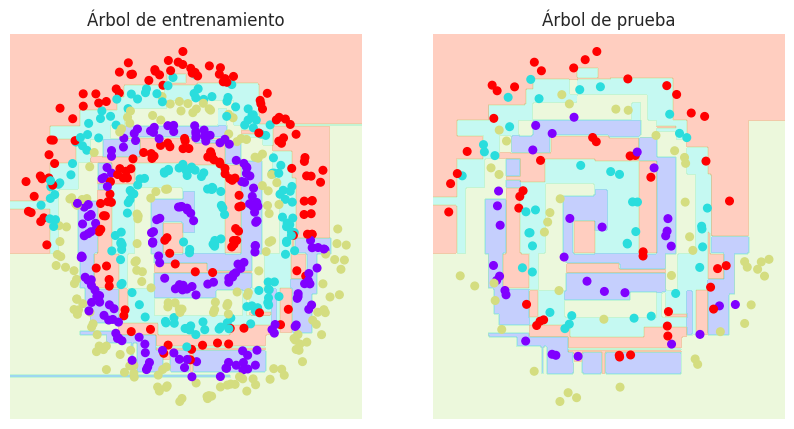

In [72]:
#Modelo 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))
visualize_classifier(tree, X_train, Y_train, ax=ax1)
visualize_classifier(tree, X_test, Y_test, ax=ax2)
ax1.set_title("Árbol de entrenamiento")
ax2.set_title("Árbol de prueba")
plt.show()


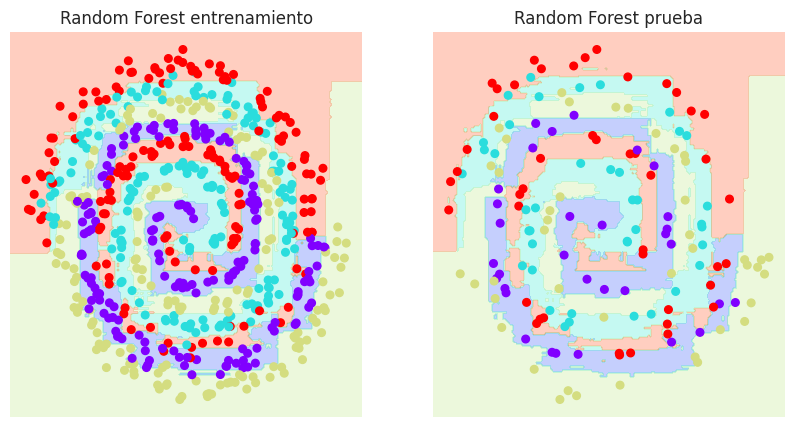

In [71]:
#Modelo 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))
visualize_classifier(forest, X_train, Y_train, ax=ax1)
visualize_classifier(forest, X_test, Y_test, ax=ax2)
ax1.set_title("Random Forest entrenamiento")
ax2.set_title("Random Forest prueba")
plt.show()


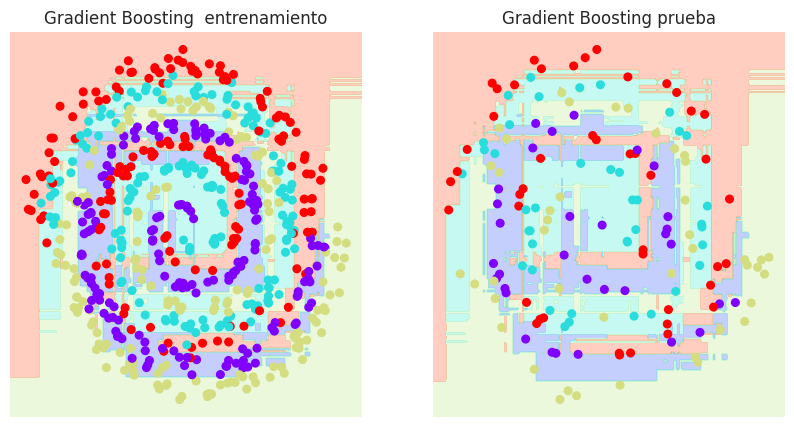

In [70]:
#Modelo 3

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))
visualize_classifier(grad_boosting, X_train, Y_train, ax=ax1)
visualize_classifier(grad_boosting, X_test, Y_test, ax=ax2)
ax1.set_title("Gradient Boosting  entrenamiento")
ax2.set_title("Gradient Boosting prueba")
plt.show()

En este caso, el sobreajuste en los 3 modelos se concentra en el centro, donde las distintas clases se mezclan, por lo que pocas observaciones influyen considerablemente en la determinación de la frontera. Además, en la zona externa de los gráficos, estos pocos puntos afectan considerablemente a los bloques, a pesar de que su peso no es suficiente como para ajustar la región. En los modelos, el sobreajuste causa una mayor fragmentación en las regiones que contienen los puntos.

Con respecto a las características de los sectores, para el árbol de decisión tenemos bloques rectangulares donde, en la etapa de prueba, se presenta una caída de puntos en sectores distintos a los suyos. Esto puede ser explicado por el tipo de modelo, que memoriza los datos de entrenamiento. Por su lado, el modelo de Random Forest muestra sectores más suavizados, es decir, donde ya no se aprecian los rectángulos del modelo de árbol de decisión; no obstante, tenemos el mismo problema mencionado anteriormente, donde las categorías se entremezclan en la zona interior.

Por su lado, el modelo de Gradient Boosting presenta los sectores más fragmentados, con líneas que se intercalan en los sectores centrales del gráfico, por lo que vemos cómo el ruido desplaza a las observaciones hasta concentrarlas en otro sector y agrega regiones adicionales para concentrarlas.

**6. Realiza un análisis de sensibilidad de los modelos con respecto a las características de los datos. Para esto, modifique el conjunto de datos utilizando los parámetros que recibe la función que genera espirales. Específicamente, estudie el efecto del ruido y de la forma de las espirales.**

Accuracy_train=1.00 | Accuracy_test=0.69


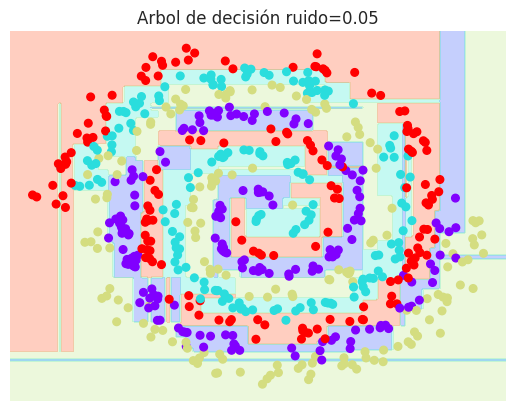

Accuracy_train=1.00 | Accuracy_test=0.77


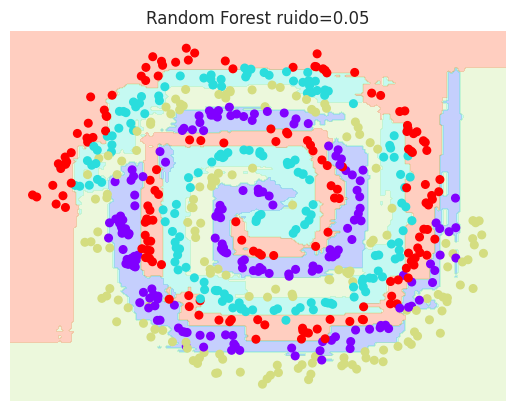

Accuracy_train=0.92 | Accuracy_test=0.68


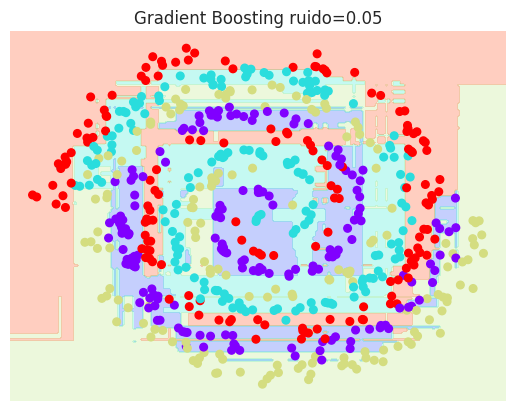

Accuracy_train=1.00 | Accuracy_test=0.87


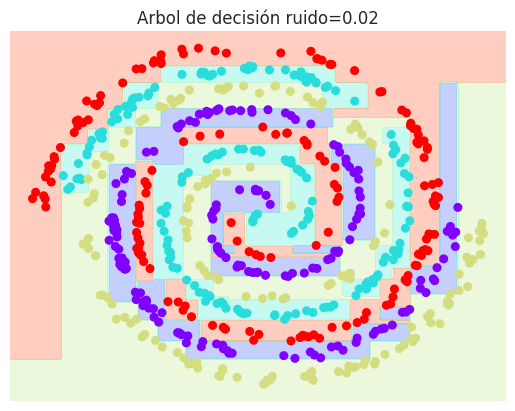

Accuracy_train=1.00 | Accuracy_test=0.88


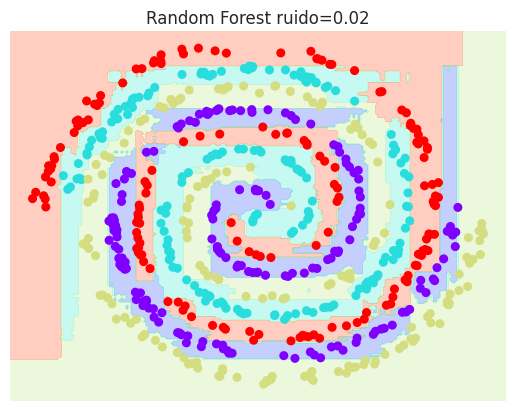

Accuracy_train=0.96 | Accuracy_test=0.75


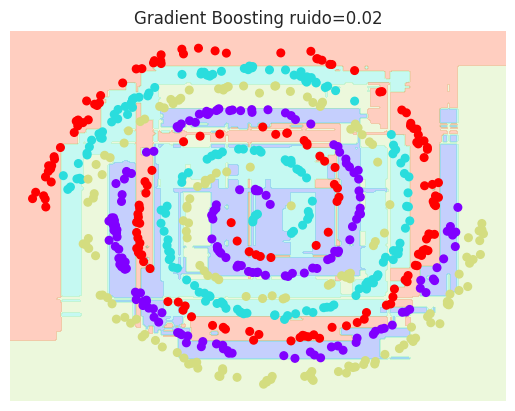

Accuracy_train=1.00 | Accuracy_test=0.90


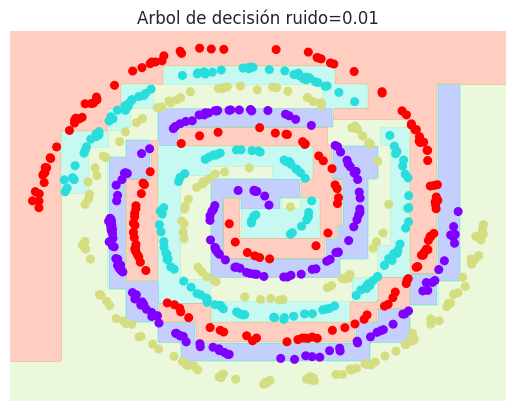

Accuracy_train=1.00 | Accuracy_test=0.88


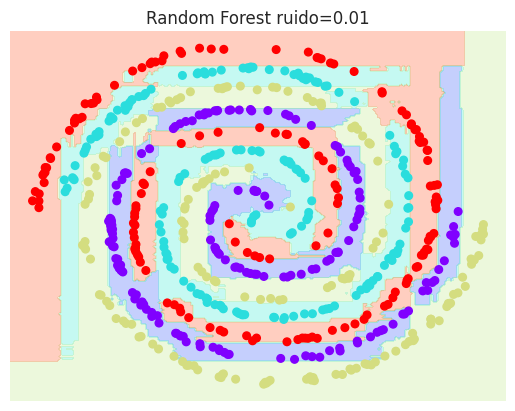

Accuracy_train=0.95 | Accuracy_test=0.71


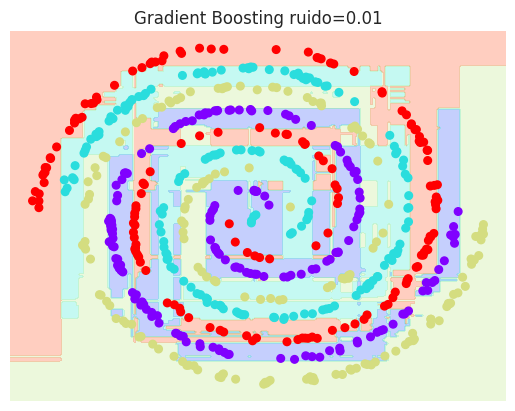

In [81]:
nivel_ruido=[0.05, 0.02,0.01]

def generate_spiral2(a, b, N, noise_factor):
    theta = np.sqrt(np.random.rand(N))*4*np.pi
    r = a + b*theta
    x = np.array([np.cos(theta)*r, np.sin(theta)*r]).T
    x += np.expand_dims(noise_factor*r, 1)*np.random.randn(N, 2)
    return x

for ruido in nivel_ruido:
  np.random.seed(random_state)
  x1 = generate_spiral2(0, b, N, ruido)
  x2 = generate_spiral2(0, -b, N, ruido)
  x3 = generate_spiral2(a, b, N, ruido)
  x4 = generate_spiral2(-a, -b, N, ruido)

  X_r = np.concatenate((x1, x2, x3, x4), axis=0)
  Y_r = np.ravel(np.concatenate((np.zeros((N,1)), np.ones((N,1)), 2*np.ones((N,1)), 3*np.ones((N,1))), axis=0))

  X_train_r, X_test_r, Y_train_r, Y_test_r = train_test_split(X_r, Y_r, test_size=0.2, random_state=random_state)

  ##fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))#
  #ax1.scatter(X_r[:, 0], X_r[:, 1], c=Y_r)#
  #ax1.set_title(f"Datos completos nuevo test(ruido={ruido})")
  #ax2.scatter(X_test_r[:, 0], X_test_r[:, 1], c=Y_test_r)
  #ax2.set_title(f"Prueba con nuevos datos(ruido={ruido})")
  #plt.show()#

  tree_r=DecisionTreeClassifier(random_state=random_state)
  train_y_eval(tree_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(tree_r, X_train_r, Y_train_r)
  plt.title(f"Arbol de decisión ruido={ruido}")
  plt.show()
  ##Modelo 2
  forest_r= RandomForestClassifier(random_state=random_state)
  train_y_eval(forest_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(forest_r, X_train_r, Y_train_r)
  plt.title(f"Random Forest ruido={ruido}")
  plt.show()
  ##Modelo 3

  grad_boosting_r=GradientBoostingClassifier(random_state=random_state)
  train_y_eval(grad_boosting_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(grad_boosting_r, X_train_r, Y_train_r)
  plt.title(f"Gradient Boosting ruido={ruido}")

  plt.show()



Al controlar por el ruido, vemos como con el nivel de ruido de 0,05 los puntos se mezclan con otras regiones, mientras que conforme va disminuyendo a 0,02 y 0,01 las espirales van disminuyendo los errores en asignación de los puntos según su correspondiente región. En este caso, el gradient boosting es el que presenta la visualización más fragmentada para todos los niveles de ruido, por lo que existe la mayor mezcla de puntos en diferentes secciones.

Accuracy_train=1.00 | Accuracy_test=0.66


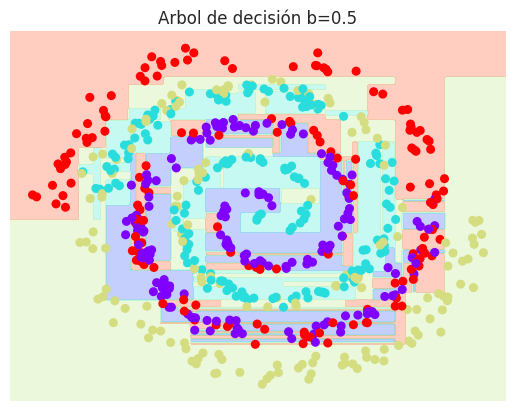

Accuracy_train=1.00 | Accuracy_test=0.68


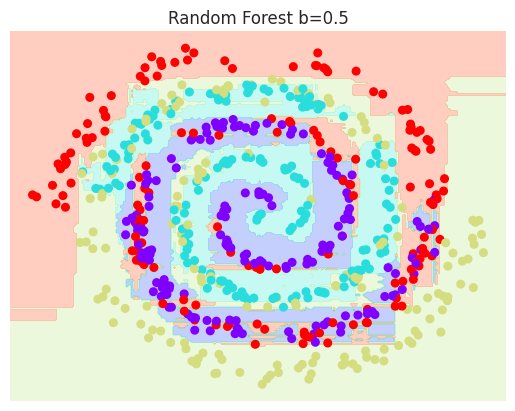

Accuracy_train=0.92 | Accuracy_test=0.64


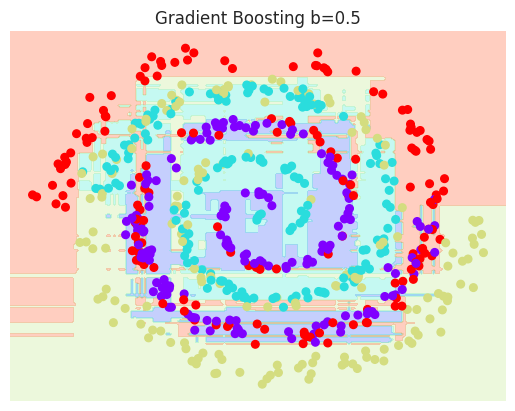

Accuracy_train=1.00 | Accuracy_test=0.69


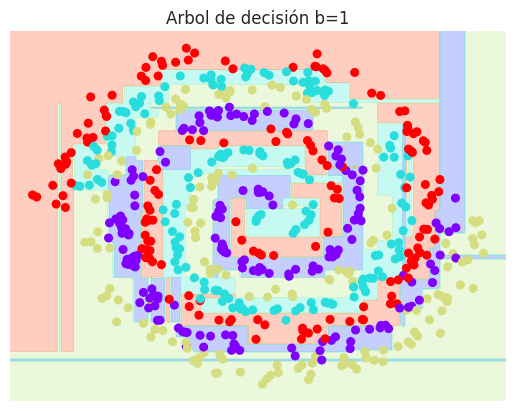

Accuracy_train=1.00 | Accuracy_test=0.77


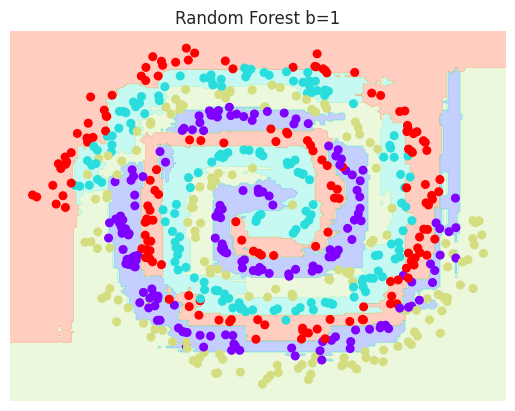

Accuracy_train=0.92 | Accuracy_test=0.68


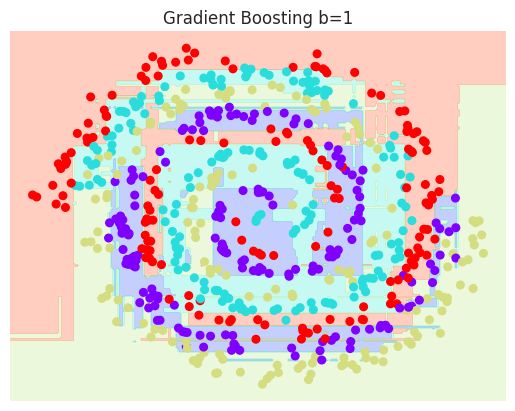

Accuracy_train=1.00 | Accuracy_test=0.73


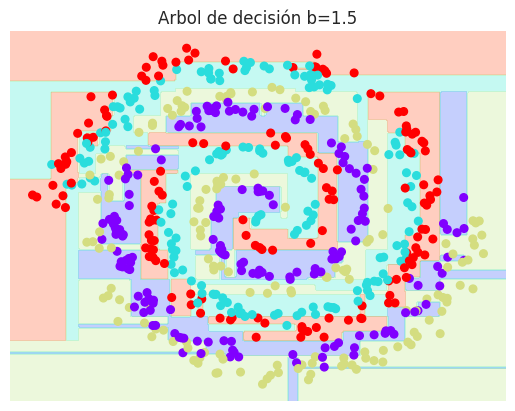

Accuracy_train=1.00 | Accuracy_test=0.72


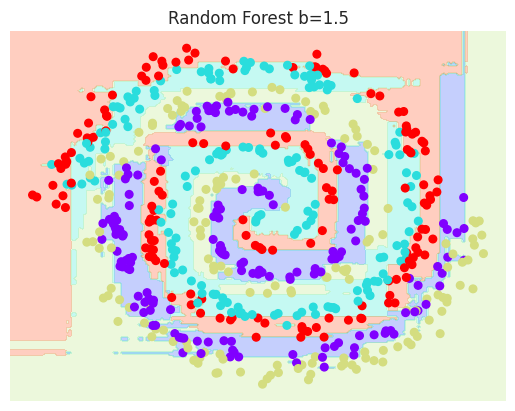

Accuracy_train=0.92 | Accuracy_test=0.57


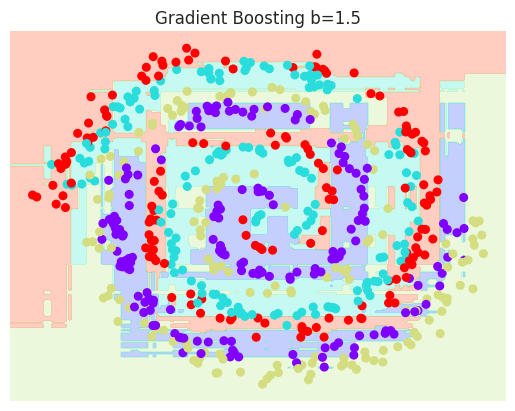

In [80]:
ruido=0.05
nivel_b= [0.5,1,1.5]

for b_n in nivel_b:
  np.random.seed(random_state)
  x1 = generate_spiral2(0, b_n, N, ruido)
  x2 = generate_spiral2(0, -b_n, N, ruido)
  x3 = generate_spiral2(a, b_n, N, ruido)
  x4 = generate_spiral2(-a, -b_n, N, ruido)

  X_r = np.concatenate((x1, x2, x3, x4), axis=0)
  Y_r = np.ravel(np.concatenate((np.zeros((N,1)), np.ones((N,1)), 2*np.ones((N,1)), 3*np.ones((N,1))), axis=0))

  X_train_r, X_test_r, Y_train_r, Y_test_r = train_test_split(X_r, Y_r, test_size=0.2, random_state=random_state)
  #modelo 1
  tree_r=DecisionTreeClassifier(random_state=random_state)
  train_y_eval(tree_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(tree_r, X_train_r, Y_train_r)
  plt.title(f"Arbol de decisión b={b_n}")
  plt.show()
  ##Modelo 2
  forest_r= RandomForestClassifier(random_state=random_state)
  train_y_eval(forest_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(forest_r, X_train_r, Y_train_r)
  plt.title(f"Random Forest b={b_n}")
  plt.show()
  ##Modelo 3

  grad_boosting_r=GradientBoostingClassifier(random_state=random_state)
  train_y_eval(grad_boosting_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(grad_boosting_r, X_train_r, Y_train_r)
  plt.title(f"Gradient Boosting b={b_n}")

  plt.show()

Al cambiar la variable b en las espirales, lo que tenemos es que estas vueltas se separan más. Esto se debe a que ahora las regiones para los datos aumentan conforme aumenta b, lo que permite que no se mezclan en tanta medida los datos con sus respectivos segmentos.

Accuracy_train=1.00 | Accuracy_test=0.71


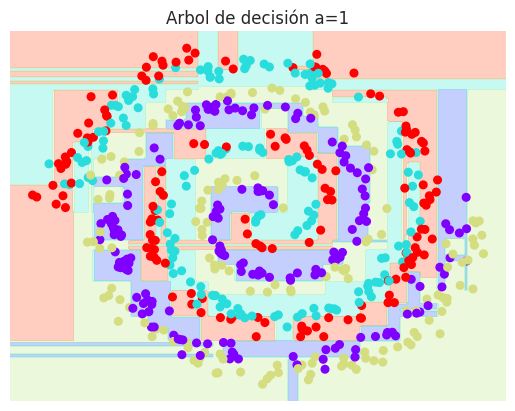

Accuracy_train=1.00 | Accuracy_test=0.71


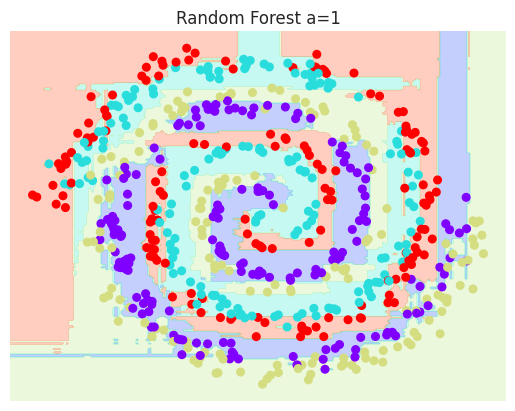

Accuracy_train=0.89 | Accuracy_test=0.55


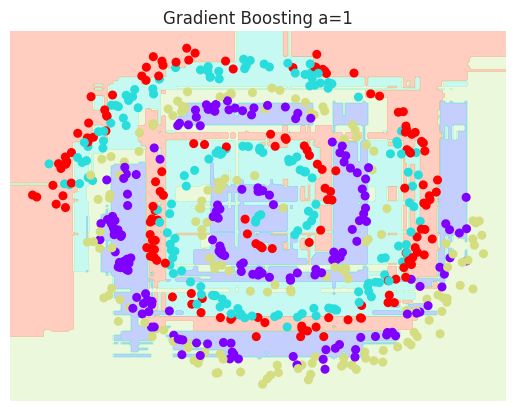

Accuracy_train=1.00 | Accuracy_test=0.69


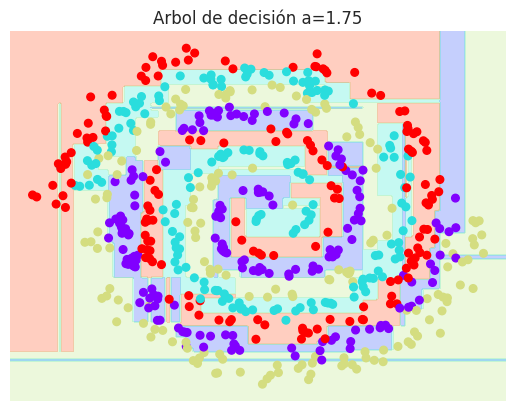

Accuracy_train=1.00 | Accuracy_test=0.77


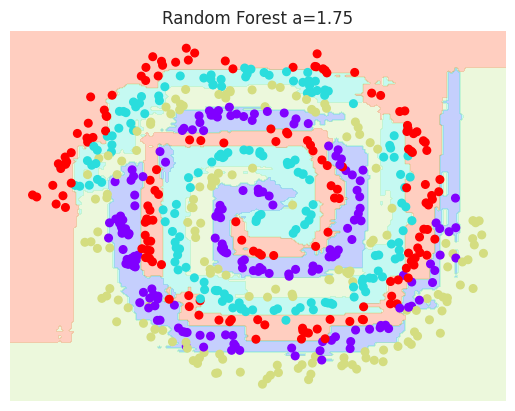

Accuracy_train=0.92 | Accuracy_test=0.68


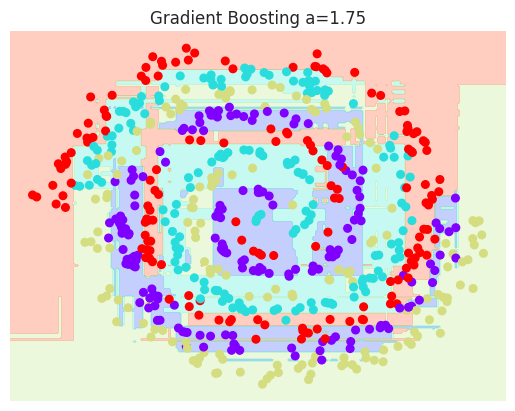

Accuracy_train=1.00 | Accuracy_test=0.72


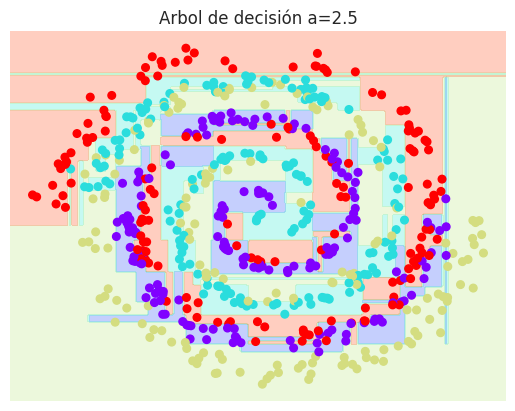

Accuracy_train=1.00 | Accuracy_test=0.74


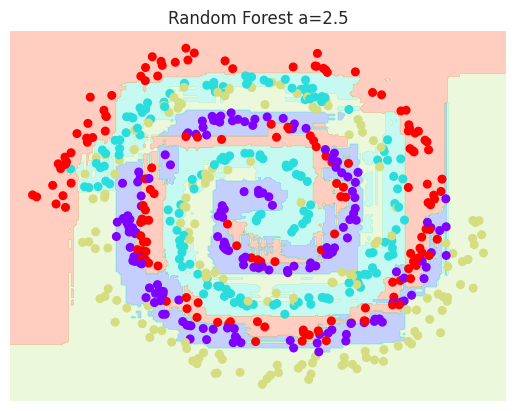

Accuracy_train=0.92 | Accuracy_test=0.68


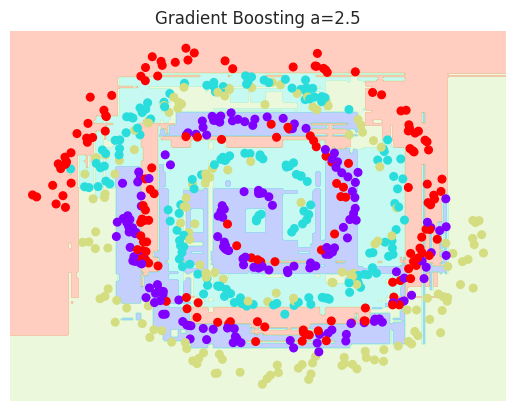

In [79]:
ruido=0.05
nivel_a= [1,1.75,2.5]

for a_n in nivel_a:
  np.random.seed(random_state)
  x1 = generate_spiral2(0, b, N, ruido)
  x2 = generate_spiral2(0, -b, N, ruido)
  x3 = generate_spiral2(a_n, b, N, ruido)
  x4 = generate_spiral2(-a_n, -b, N, ruido)

  X_r = np.concatenate((x1, x2, x3, x4), axis=0)
  Y_r = np.ravel(np.concatenate((np.zeros((N,1)), np.ones((N,1)), 2*np.ones((N,1)), 3*np.ones((N,1))), axis=0))

  X_train_r, X_test_r, Y_train_r, Y_test_r = train_test_split(X_r, Y_r, test_size=0.2, random_state=random_state)
  #modelo 1
  tree_r=DecisionTreeClassifier(random_state=random_state)
  train_y_eval(tree_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(tree_r, X_train_r, Y_train_r)
  plt.title(f"Arbol de decisión a={a_n}")
  plt.show()
  ##Modelo 2
  forest_r= RandomForestClassifier(random_state=random_state)
  train_y_eval(forest_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(forest_r, X_train_r, Y_train_r)
  plt.title(f"Random Forest a={a_n}")
  plt.show()
  ##Modelo 3

  grad_boosting_r=GradientBoostingClassifier(random_state=random_state)
  train_y_eval(grad_boosting_r, X_train_r, Y_train_r, X_test_r, Y_test_r)
  visualize_classifier(grad_boosting_r, X_train_r, Y_train_r)
  plt.title(f"Gradient Boosting a={a_n}")

  plt.show()

Controlando por la variable a, vemos que no se nota efecto significativo de esta variable en el rendimiento de los distintos modelos, a su vez, vemos como la fragmentación de los gráficos aumenta conforme incrementamos a. En este caso, controlar por a no disminuye los niveles de sobreajuste del modelo, debido a que se mantiene una brecha significativa entre el accuracy en la etapa de entrenamiento y de prueba.